In [18]:
import numpy as np
import matplotlib.pyplot as plt

In [11]:
class Source:
    "Источник изотропного излучения фотонов"
    def __init__(self, Y: float = 10000):
        self.Y = Y

    def random_direction(self, E: float) ->np.ndarray:
        """Розыгрыш начального направления"""
        if E < 0:
            raise ValueError("Энергия может быть отрицательной")

        N = int(round(self.Y * E))

        phi = np.random.uniform(0, 2*np.pi, N)
        cosTheta = np.random.uniform(-1, 1, N)
        sinTheta = np.sqrt(1 - cosTheta**2)
        return np.array([sinTheta*np.cos(phi),
                         sinTheta*np.sin(phi),
                         cosTheta])

In [12]:
source = Source(10000)

E = 1.0
directions = source.random_direction(E)

In [17]:
print("Энергия события:", E, "МэВ")
print("Количество фотонов:", len(directions))
print("Форма массива:", directions.shape)

Энергия события: 1.0 МэВ
Количество фотонов: 3
Форма массива: (3, 10000)


In [16]:
def test_source():
    source = Source()
    directions = source.random_direction(E=1.0)

    assert directions.shape == (3, 10000)

    norms = np.linalg.norm(directions, axis=0)
    assert np.allclose(norms, 1.0)

    # Проверка изотропности
    mean_direction = np.mean(directions, axis=1)
    assert np.all(np.abs(mean_direction) < 0.03)

    assert source.random_direction(0).shape == (3, 0)

    print("Среднее направление:", mean_direction)

test_source()

Среднее направление: [-0.00016047 -0.00752399  0.00023471]


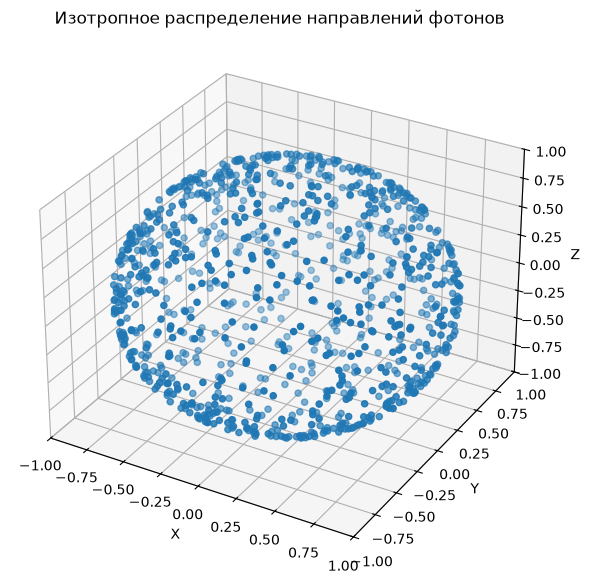

In [ ]:
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

# возьмем первые 1000 фотонов
n=1000
ax.scatter(
    directions[0, :n],
    directions[1, :n],
    directions[2, :n]
)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Изотропное распределение направлений фотонов')

ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.set_zlim(-1, 1)

plt.show()